# Ders 04 · Ters problem — Bi'yi iç sıcaklıklardan geri bulmak

**Kolay PINN · Türkişi Engineering** · Lisans + yüksek lisans · Adım 7

Ders 03'te kayıptaki Bi yanlışken ölçümlerin hatayı ancak ~2 kat düşürebildiğini gördük: yanlış Robin terimi ile veri
birbiriyle çekişiyordu. Bugün çekişmeyi kaldırıyoruz — Bi'yi ağ ağırlıklarıyla birlikte **öğreniyoruz**:

$$
\min_{\mathbf{w},\,s}\ \mathcal{L}_{\mathrm{PDE}}
+ \lambda\,\frac{1}{N_b}\sum_m\Big(\frac{\partial\hat\theta}{\partial\eta} - e^{s}\,\hat\theta\Big)^2
+ \mu\,\frac{1}{N_d}\sum_{i=1}^{N_d}\big(\hat\theta(\mathbf{x}_i) - \theta_i^{\mathrm{ö}}\big)^2,
\qquad \mathrm{Bi} = e^{s}
$$

**Öğrenme hedefleri**
1. Bi'yi pozitifliği garanti eden bir parametre olarak öğrenmek
2. Ölçümlerin Bi hakkındaki bilgisini deneyden önce hesaplamak: duyarlılık $\partial\theta/\partial\mathrm{Bi}$ ve Cramér–Rao sınırı
3. Köşe çelişkisinin Bi'yi neden aşağı çektiğini görmek
4. PINN'i aynı verilerle klasik bir yöntemle (FDM + en küçük kareler) karşılaştırmak

> Defterdeki eğitim kısaltılmıştır (~2 dk, CPU). Tam koşular (`runs/inv_*`, her biri ~8 dk) özetten yüklenir.

In [1]:
import sys, json, time, logging, warnings, types
from pathlib import Path
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=UserWarning)

CASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
ROOT = CASE.parents[1]
sys.path.insert(0, str(ROOT)); sys.path.insert(0, str(CASE))

import numpy as np
import torch
import matplotlib.pyplot as plt
from IPython.display import Image, display

from kolay_pinn.style import use_slide_style, C, INK, MUTED
from fdm_solver import BI_DEFAULT as Bi, solve_fdm
from pinn_forward import evaluate
from pinn_hybrid import sensors
import pinn_inverse

use_slide_style(); plt.rcParams["figure.dpi"] = 110
torch.set_default_dtype(torch.float64)
ASSETS = CASE / "lecture" / "ders04" / "assets"
def goster(ad, genislik=760):
    display(Image(filename=str(ASSETS / ad), width=genislik))
S = json.loads((CASE / "data" / "summary_inverse.json").read_text())
CL = json.loads((CASE / "data" / "inverse_classical.json").read_text())
print(f"torch {torch.__version__} · gerçek Bi = {Bi:.4f}")

torch 2.15.0+cu132 · gerçek Bi = 4.8945


---
## 1 · Bi'yi parametre yap

### 1.1 Neden $\mathrm{Bi} = e^{s}$?

- Bi negatif olamaz; $e^{s}$ her $s$ için pozitif.
- $\partial\mathcal{L}/\partial s = \mathrm{Bi}\,\partial\mathcal{L}/\partial\mathrm{Bi}$: adım **göreli** olur. Bi = 1'de de 10'da da benzer yüzdelik adımlar.

`pinn_inverse.train` içinde tek değişiklik bu:

```python
s = torch.nn.Parameter(torch.tensor(math.log(args.bi0)))      # Bi = exp(s)
r_pde, r_rob = residuals(model, X_int, X_bot, s.exp())
opt = torch.optim.Adam([{"params": model.parameters()}, {"params": [s], "lr": 1e-2}], lr=1e-3)
```

$s$'nin öğrenme oranı ağınkinden 10 kat büyük: ağın binlerce ağırlığı varken $s$ tek bir sayı ve hızlı hareket etmesi gerekiyor.

### 1.2 Kısa bir eğitim

20 düzgün sensör, $\sigma = 0.01$ (0.5 °C), Bi₀ = 1:

In [2]:
X_d, y_d, temiz = sensors(20, "uniform", 0.01, seed=0)
args = types.SimpleNamespace(seed=0, width=50, depth=4, bi0=1.0, n_int=4096, n_bot=256, skip=0.02,
                             lam=1.0, mu=100.0, lr=1e-3, lr_bi=1e-2, adam=1500, lbfgs=400, Bi=Bi)
t0 = time.perf_counter()
model, Bi_hat, hist, info = pinn_inverse.train(args, X_d, y_d)
m = evaluate(model, Bi)[0]
print(f"\nkısa eğitim: Bi = {Bi_hat:.3f} (gerçek {Bi:.3f}, hata %{100 * abs(Bi_hat - Bi) / Bi:.1f}) · "
      f"bağıl L2 {m['rel_L2']:.1e} · {time.perf_counter() - t0:.0f} s")

Adam      0  L = 3.614e+00  Bi = 0.9900  (PDE 2.04e-02, Robin 9.46e-01, veri 2.65e-02)


Adam   1000  L = 5.675e-01  Bi = 1.3652  (PDE 1.05e-01, Robin 2.59e-01, veri 2.03e-03)


L-BFGS bitti: L = 3.175e-02 · Bi = 4.4392 (gerçek 4.8945) · süre 134 s



kısa eğitim: Bi = 4.439 (gerçek 4.895, hata %9.3) · bağıl L2 8.8e-03 · 135 s


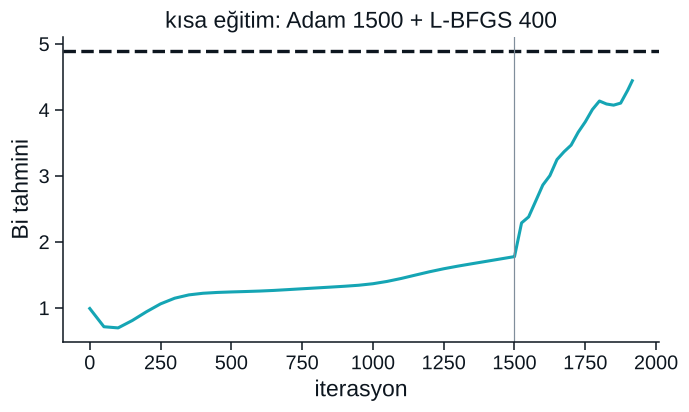

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(hist["it"], hist["Bi"], color=C["plan"], lw=2)
ax.axhline(Bi, color=INK, ls="dashed"); ax.axvline(args.adam, color=MUTED, lw=0.8)
ax.set(xlabel="iterasyon", ylabel="Bi tahmini", title="kısa eğitim: Adam 1500 + L-BFGS 400")
plt.show()

Kısa eğitimde Bi henüz gerçek değere oturmayabilir: Adam'da Bi yavaş yükselir, son yaklaşmayı L-BFGS yapar.
Tam koşular (Adam 6000 + L-BFGS 2000):

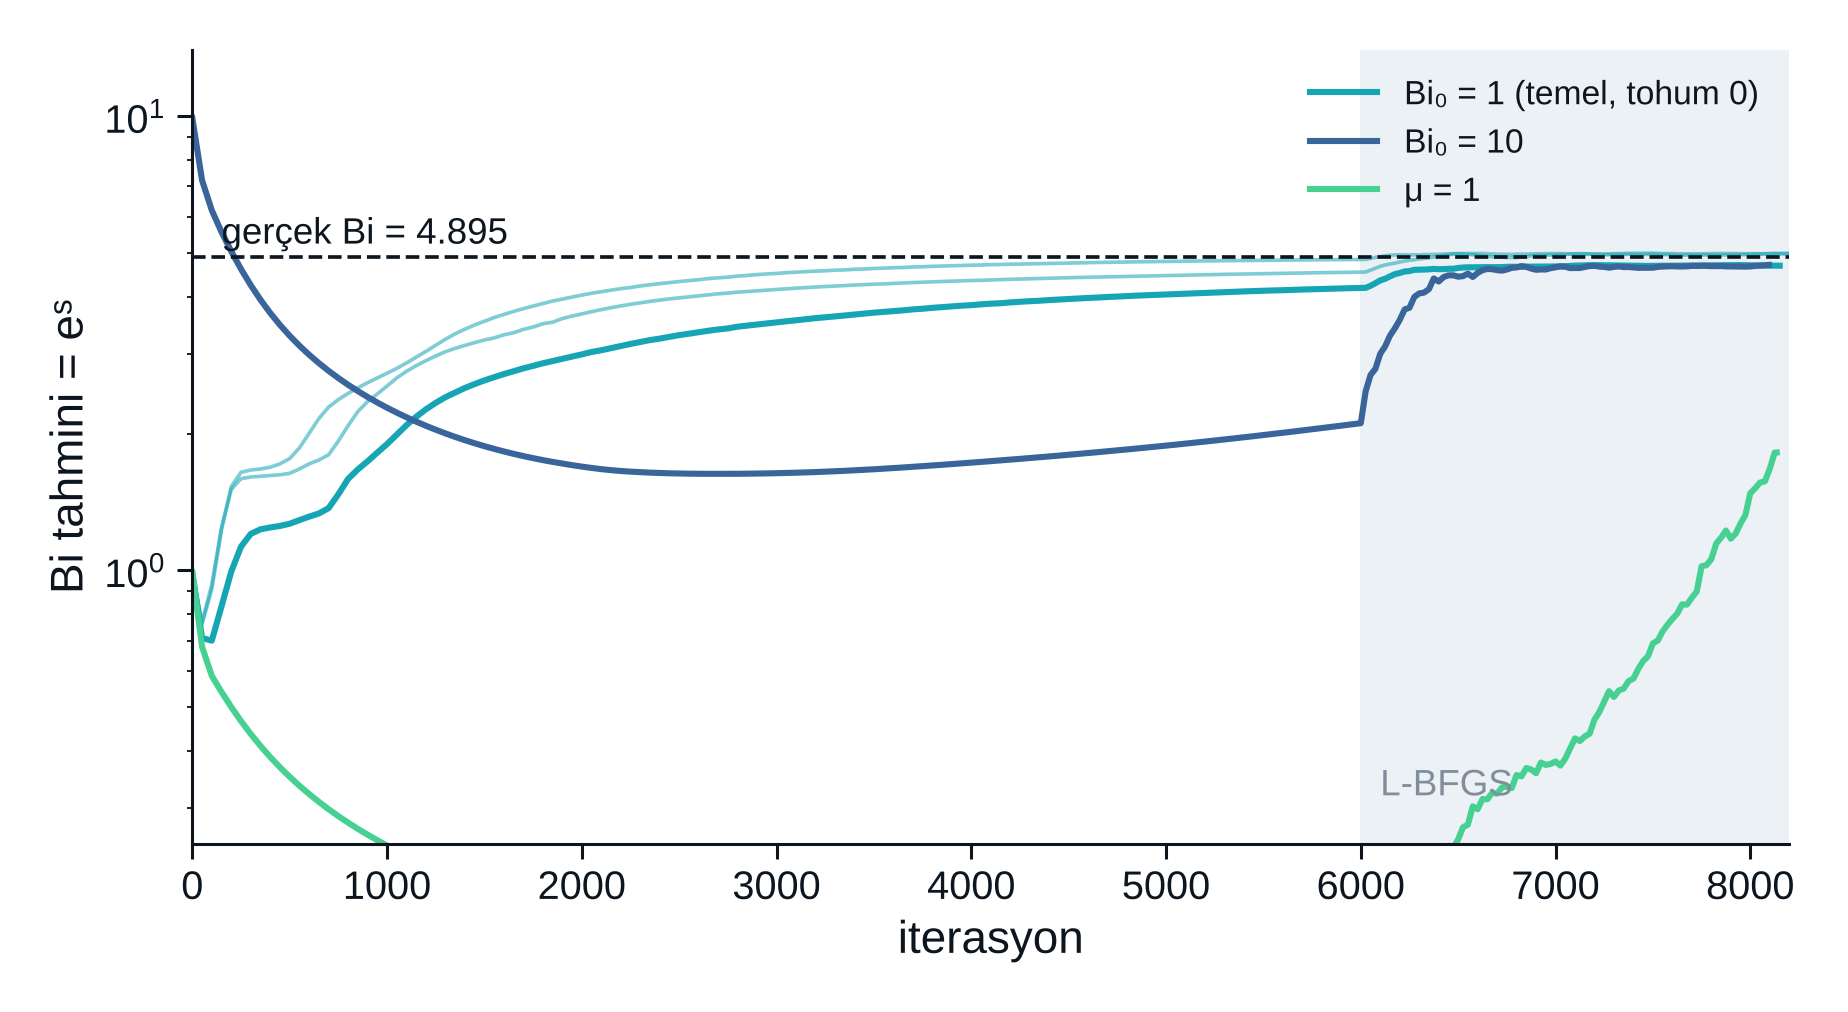

In [4]:
goster("02_trajectory.png", 700)

In [5]:
for g, v in S["groups"].items():
    print(f"{g:18s} Bi = {[round(r['Bi_hat'], 3) for r in v['runs']]}")
if S["start_bi10"]:
    print(f"\nBi₀ = 10'dan: {S['start_bi10']['Bi_hat']:.3f}  (aynı tohum, Bi₀ = 1: {S['start_bi10']['same_as_bi0_1_seed0']:.3f})")

temel 20 düzgün    Bi = [4.682, 4.972, 4.988]
köşe dışlama yok   Bi = [3.861, 4.532, 4.277]
üst yarı           Bi = [3.568, 5.145, 4.975]
alt şerit          Bi = [4.832, 4.892, 4.987]
5 sensör           Bi = [5.139, 4.936, 4.27]
80 sensör          Bi = [4.989, 4.901, 4.913]
μ = 1              Bi = [1.818, 4.27, 3.034]

Bi₀ = 10'dan: 4.701  (aynı tohum, Bi₀ = 1: 4.682)


---
## 2 · Ne kadar bilgi var?

### 2.1 Duyarlılık

Bi'yi biraz değiştirince her noktadaki sıcaklık ne kadar değişir? FDM'i iki kez çözüp merkezi farkla:

$$S(\mathbf{x}) = \frac{\partial\theta}{\partial\,\mathrm{Bi}} \approx \frac{\theta(\mathbf{x};\mathrm{Bi}+h) - \theta(\mathbf{x};\mathrm{Bi}-h)}{2h}$$

In [6]:
N = 101
h = 1e-3 * Bi
x, _, _ = solve_fdm(N, Bi)
Sm = (solve_fdm(N, Bi + h)[2] - solve_fdm(N, Bi - h)[2]) / (2 * h)
print(f"max |S| = {np.abs(Sm).max():.4f} (alt yüzey ortası) · merkez {abs(Sm[N // 2, N // 2]):.4f} · "
      f"üst yarı max {np.abs(Sm[N // 2:]).max():.4f}")

max |S| = 0.0500 (alt yüzey ortası) · merkez 0.0122 · üst yarı max 0.0122


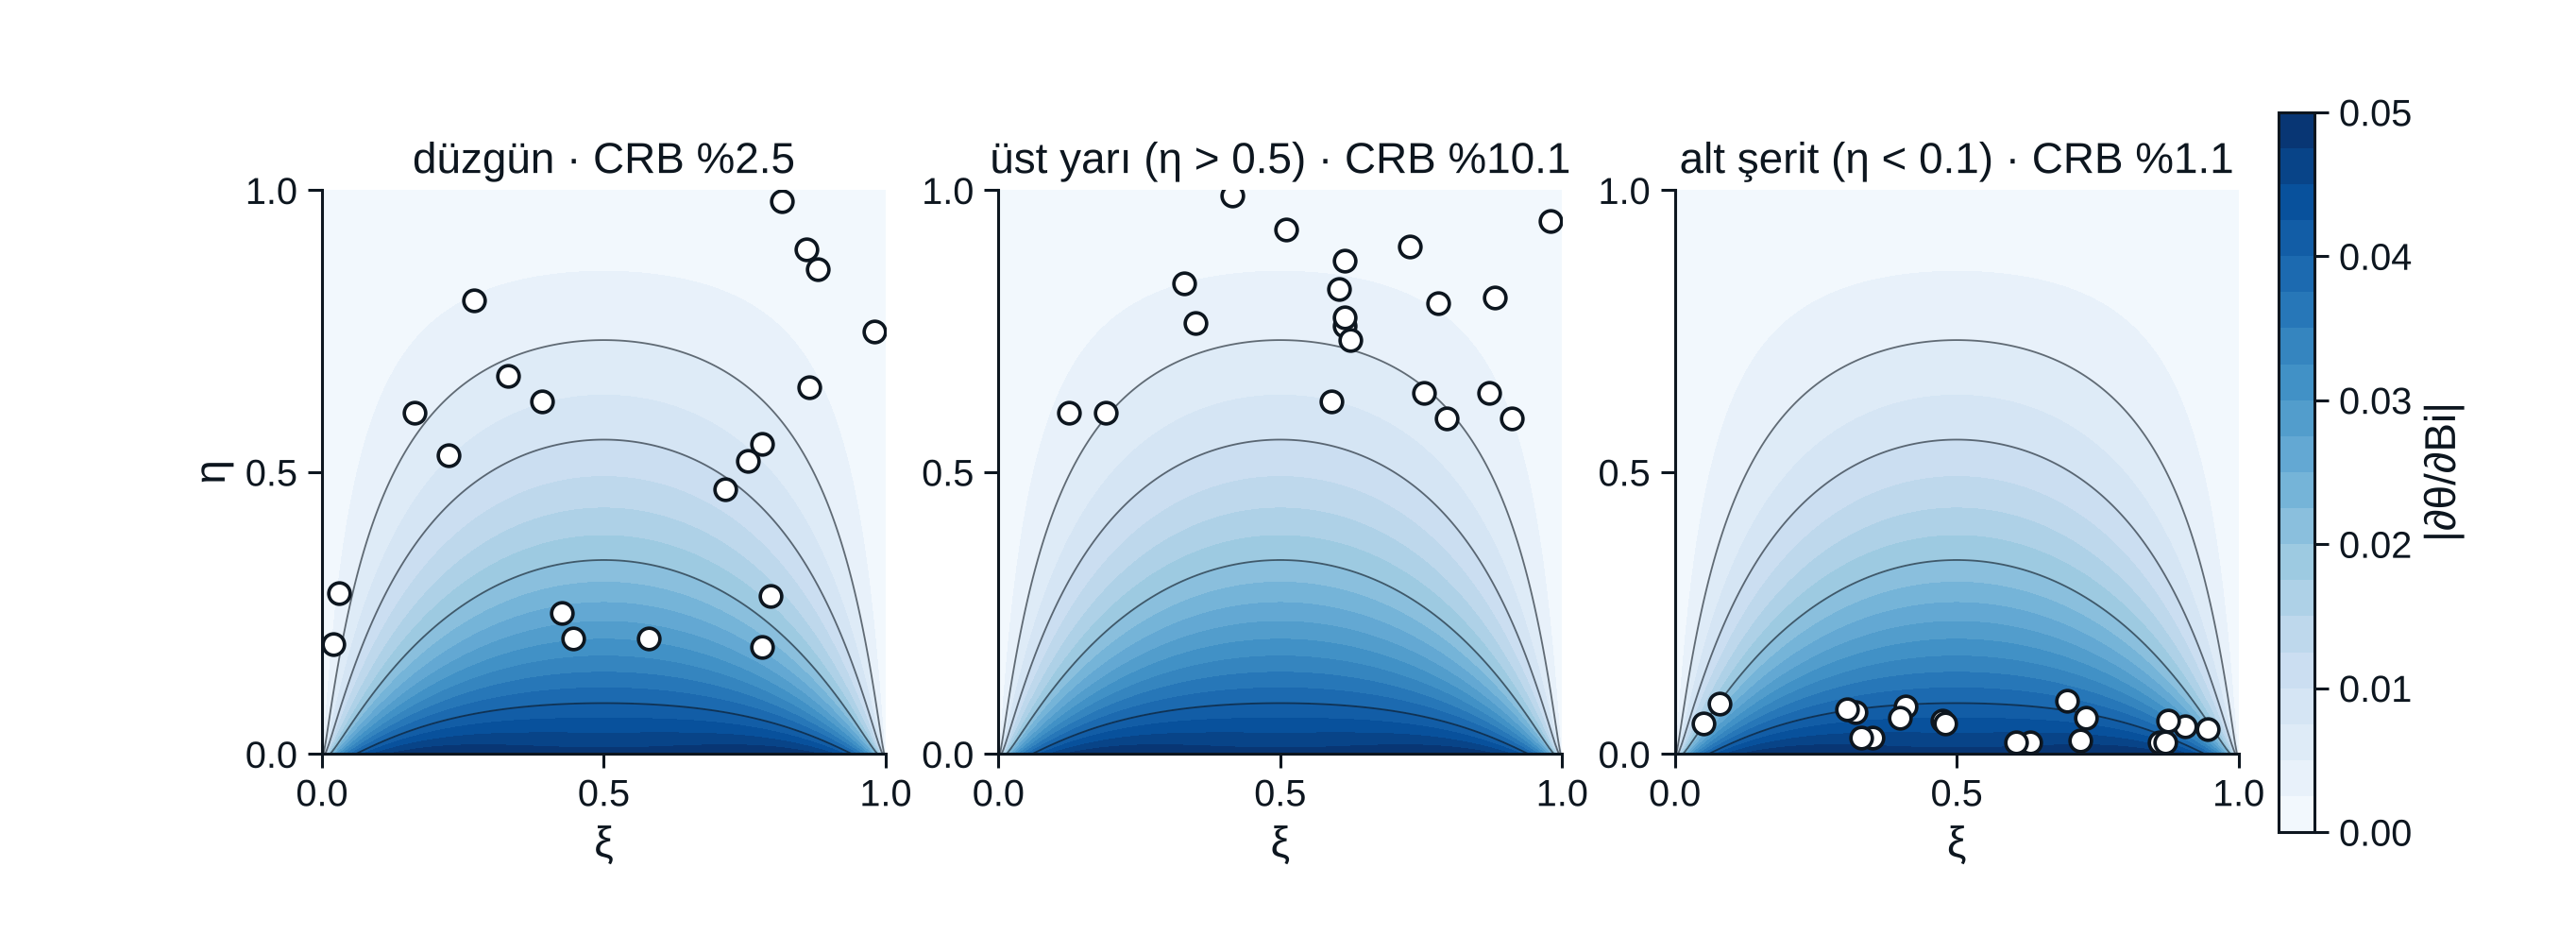

In [7]:
goster("01_sensitivity.png", 900)

Bi yalnız soğutulan yüzeyin yakınını değiştiriyor; Dirichlet duvarlarına yakın noktalar duvar sıcaklığına kilitli.

### 2.2 Cramér–Rao alt sınırı *(yüksek lisans)*

Gauss gürültüsünde Fisher bilgisi ve ondan gelen alt sınır:

$$I(\mathrm{Bi}) = \frac{1}{\sigma^2}\sum_{i=1}^{N_d} S(\mathbf{x}_i)^2, \qquad
\sigma_{\mathrm{Bi}} \ge I^{-1/2} = \frac{\sigma}{\sqrt{\sum_i S(\mathbf{x}_i)^2}}$$

Hiçbir yansız tahminci bu sensörlerle bu gürültüde daha iyisini yapamaz. Deney yapmadan hesaplanır:

In [8]:
from inverse_classical import crb, fit_fdm
for w in ("uniform", "bottom", "top"):
    for n in (5, 20, 80):
        X, _, _ = sensors(n, w, 0.01, seed=0)
        print(f"{w:8s} N_d = {n:2d}:  CRB σ_Bi/Bi = %{100 * crb(X, 0.01) / Bi:5.2f}")

uniform  N_d =  5:  CRB σ_Bi/Bi = % 6.06


uniform  N_d = 20:  CRB σ_Bi/Bi = % 3.36


uniform  N_d = 80:  CRB σ_Bi/Bi = % 1.20


bottom   N_d =  5:  CRB σ_Bi/Bi = % 2.73


bottom   N_d = 20:  CRB σ_Bi/Bi = % 1.16


bottom   N_d = 80:  CRB σ_Bi/Bi = % 0.57


top      N_d =  5:  CRB σ_Bi/Bi = %24.47


top      N_d = 20:  CRB σ_Bi/Bi = %12.67


top      N_d = 80:  CRB σ_Bi/Bi = % 5.13


Kural: sensör sayısını 4 katına çıkarmak belirsizliği yarıya indirir; sensörü duyarlılığı yüksek yere koymak da aynı
işi yapar.

### 2.3 Klasik taban: FDM + en küçük kareler

Aynı sensörlerle FDM'i bir en küçük kareler döngüsüne koyuyoruz ($\log\mathrm{Bi}$ üzerinde, `scipy.optimize.least_squares`):

In [9]:
bi_ls, t_ls, n_ev = fit_fdm(X_d, y_d)
print(f"FDM + EKK: Bi = {bi_ls:.4f} · {n_ev} FDM çözümü · {t_ls:.2f} s")
print(f"PINN (tam koşu, aynı sensörler): Bi = {S['groups']['temel 20 düzgün']['runs'][0]['Bi_hat']:.4f}")

FDM + EKK: Bi = 4.6762 · 10 FDM çözümü · 1.03 s
PINN (tam koşu, aynı sensörler): Bi = 4.6821


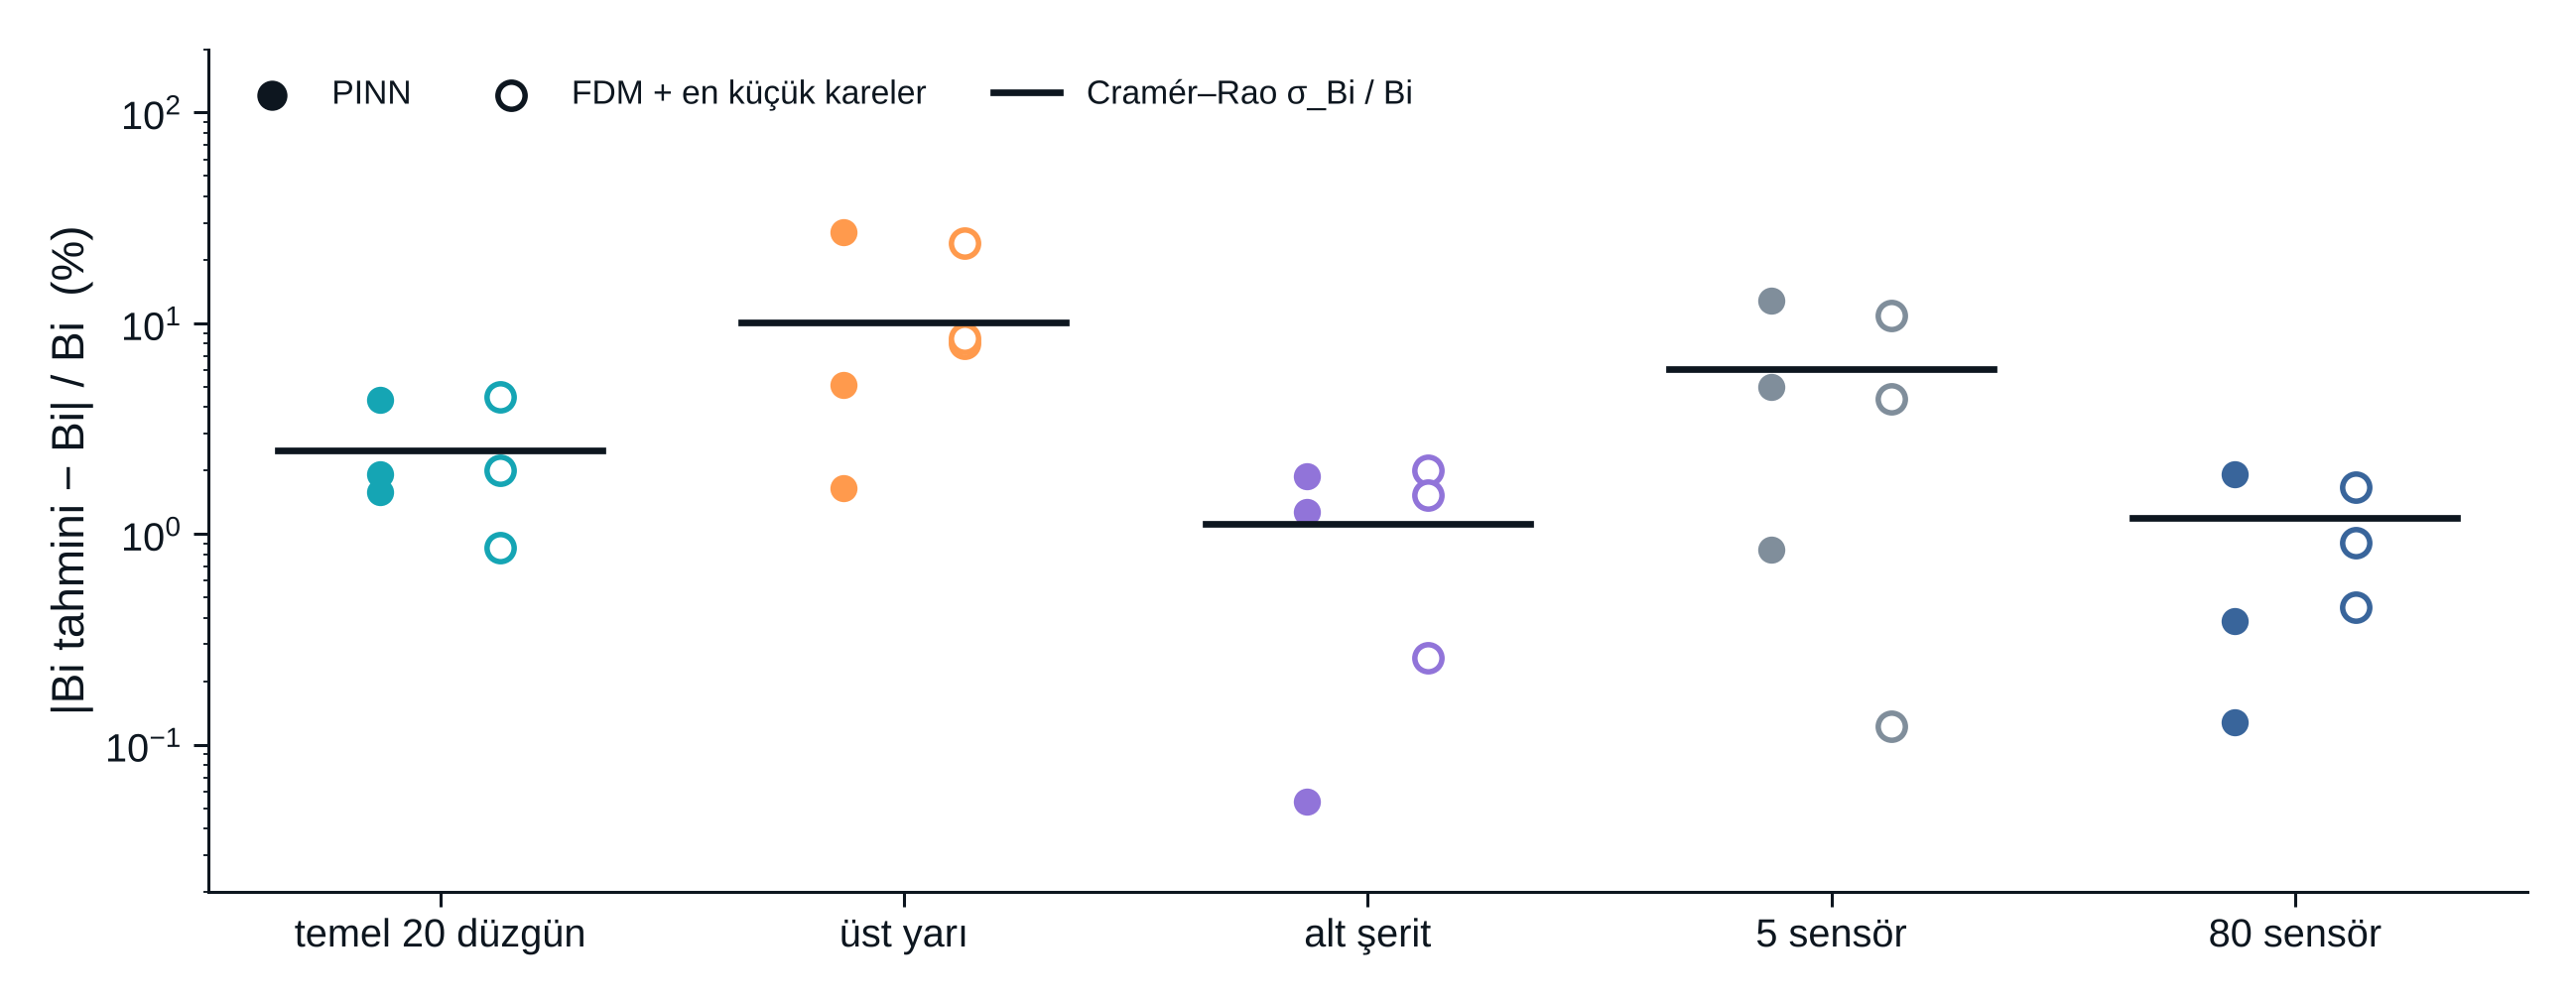

In [10]:
goster("03_error_crb.png", 900)

In [11]:
print(f"{'grup':18s} {'PINN':>7s} {'FDM-EKK':>8s} {'CRB':>6s}   (ortalama |Bi − gerçek| / Bi)")
for g, v in S["groups"].items():
    print(f"{g:18s} %{100 * v['pinn_rel_err_mean']:5.2f}  %{100 * v['fdm_ls_rel_err_mean']:5.2f}  %{100 * v['crb_rel']:4.1f}")

grup                  PINN  FDM-EKK    CRB   (ortalama |Bi − gerçek| / Bi)
temel 20 düzgün    % 2.61  % 2.45  % 2.5
köşe dışlama yok   %13.71  % 2.45  % 2.5
üst yarı           %11.29  %13.52  %10.1
alt şerit          % 1.07  % 1.27  % 1.1
5 sensör           % 6.20  % 5.13  % 6.1
80 sensör          % 0.82  % 1.01  % 1.2
μ = 1              %37.88  % 2.45  % 2.5


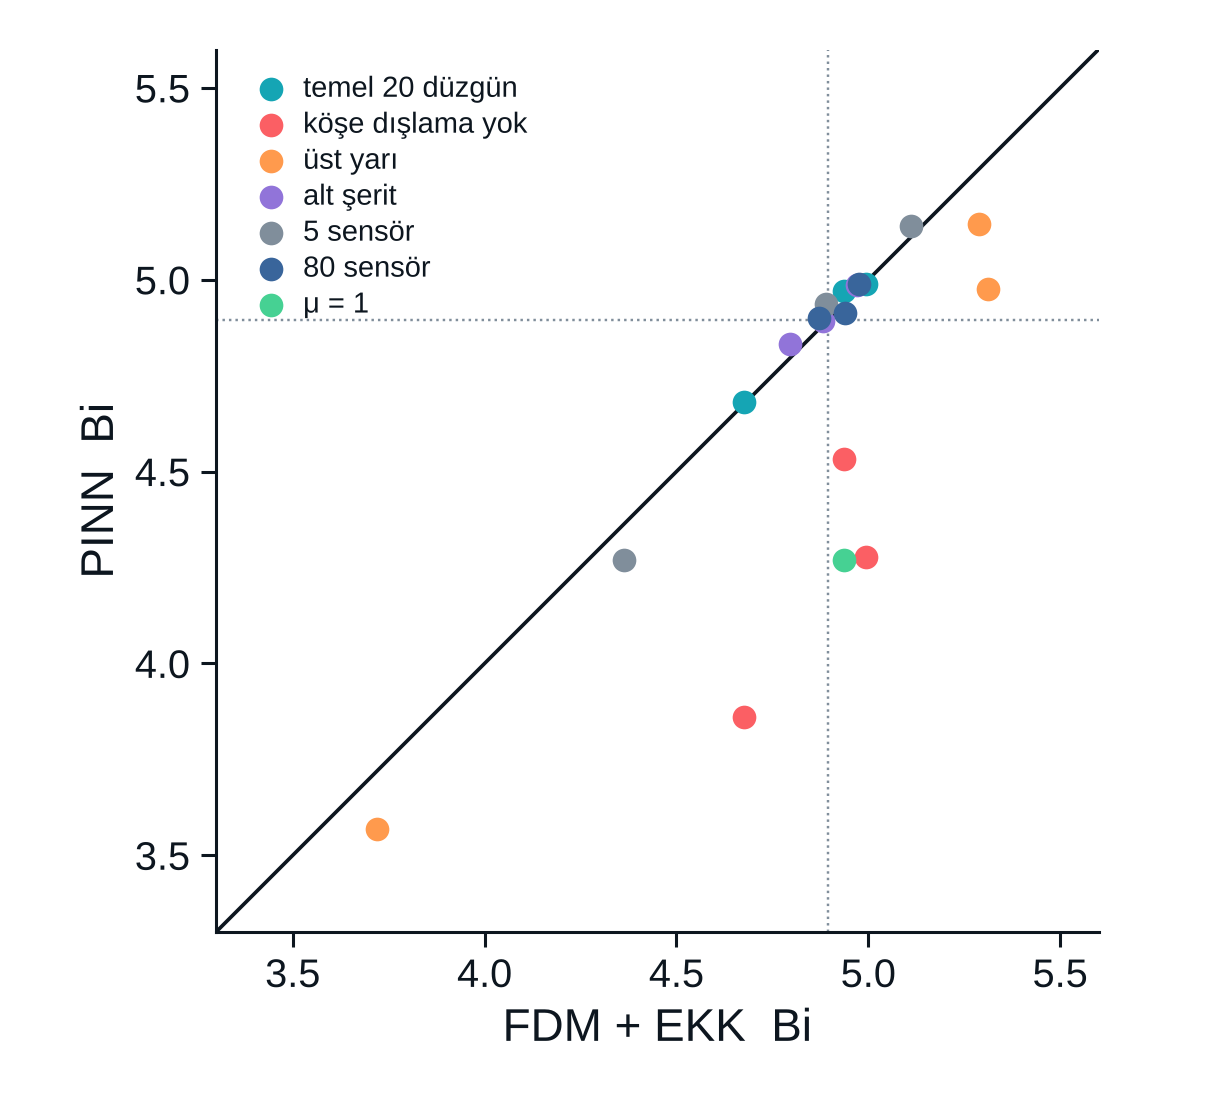

In [12]:
goster("04_parity.png", 480)

**Okuma.** Köşe dışlamalı koşularda PINN ile klasik yöntem aynı veriden neredeyse aynı Bi'yi buluyor; ikisi de
Cramér–Rao sınırı mertebesinde. Hata yöntemden değil, ölçüm gürültüsünden geliyor.

---
## 3 · Tuzaklar ve maliyet

### 3.1 Köşe yanlılığı

Alt köşede yan duvar $\theta = 1$ ve eğimi sıfır dayatıyor; Robin koşulu eğimin $\mathrm{Bi}\,\theta$ olmasını istiyor:

$$\eta = 0,\ \xi \to 0:\quad \frac{\partial\hat\theta}{\partial\eta} \to 0,\ \ \hat\theta \to 1
\;\Rightarrow\; r_{\mathrm{Robin}} \to -\mathrm{Bi},\qquad \frac{\partial r^2}{\partial\,\mathrm{Bi}} = 2\,\mathrm{Bi}\,\hat\theta^2 > 0$$

Kaybı azaltmanın kolay yolu Bi'yi küçültmek. Köşeden $\delta = 0.02$ içindeki Robin noktalarını dışlıyoruz:

In [13]:
a, b = S["groups"]["temel 20 düzgün"]["runs"], S["groups"]["köşe dışlama yok"]["runs"]
for k, (ra, rb) in enumerate(zip(a, b)):
    print(f"tohum {k}: FDM-EKK {ra['fdm_ls_Bi']:.3f} · PINN δ=0.02 {ra['Bi_hat']:.3f} · PINN δ=0 {rb['Bi_hat']:.3f}")

tohum 0: FDM-EKK 4.676 · PINN δ=0.02 4.682 · PINN δ=0 3.861
tohum 1: FDM-EKK 4.937 · PINN δ=0.02 4.972 · PINN δ=0 4.532
tohum 2: FDM-EKK 4.993 · PINN δ=0.02 4.988 · PINN δ=0 4.277


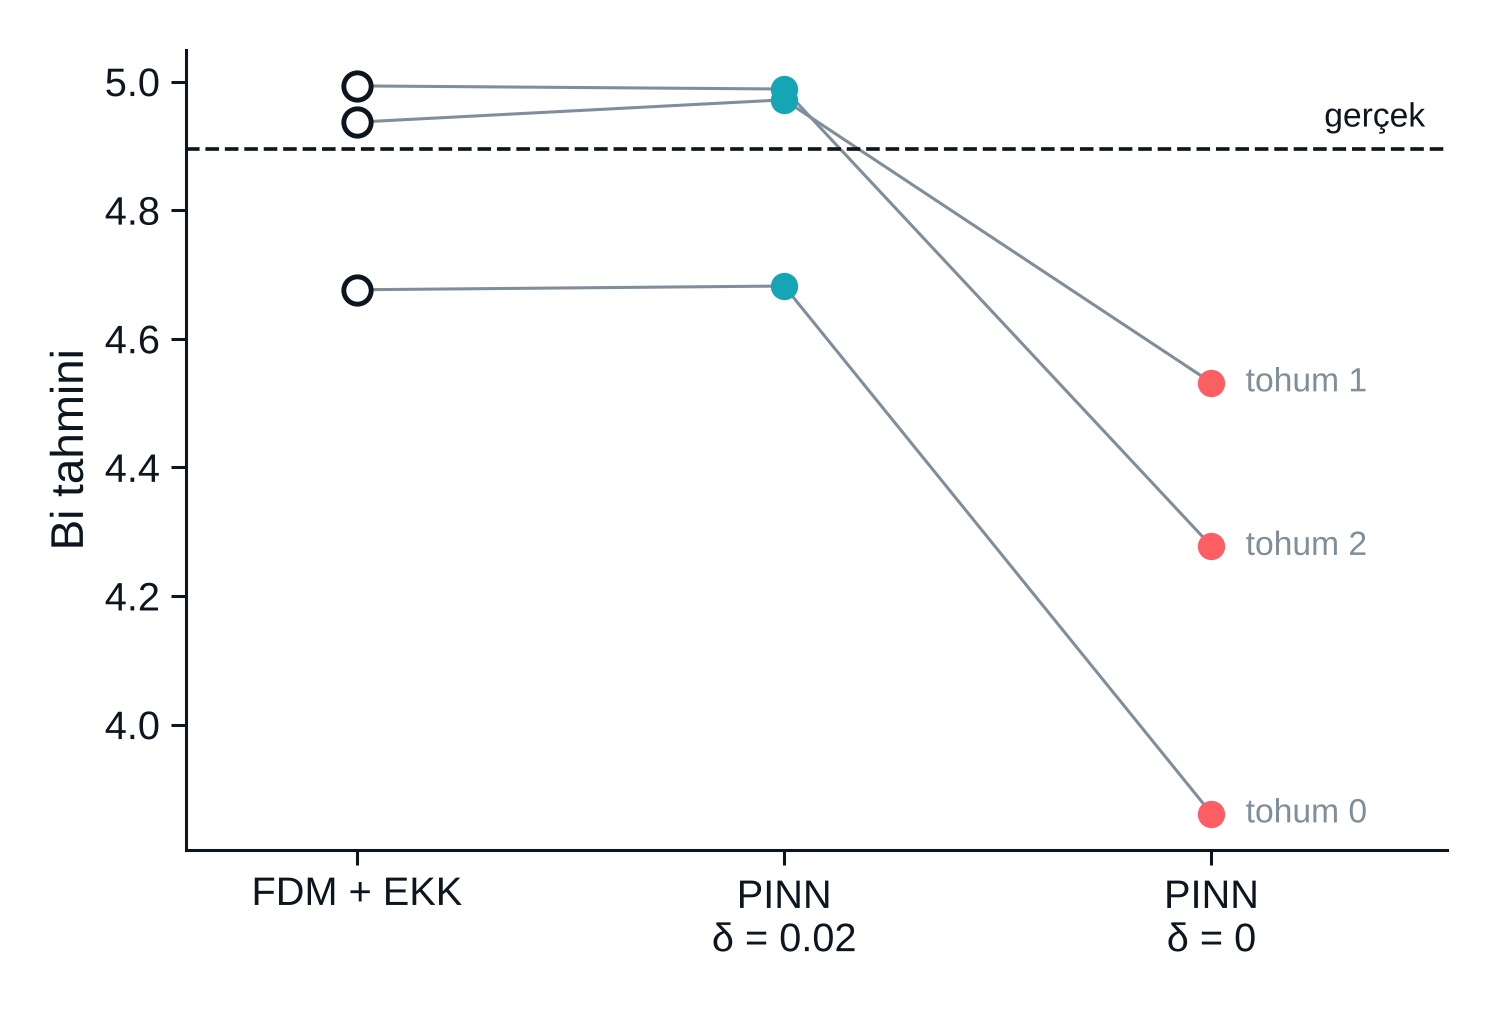

In [14]:
goster("05_corner.png", 560)

### 3.2 Gürültü ve maliyet

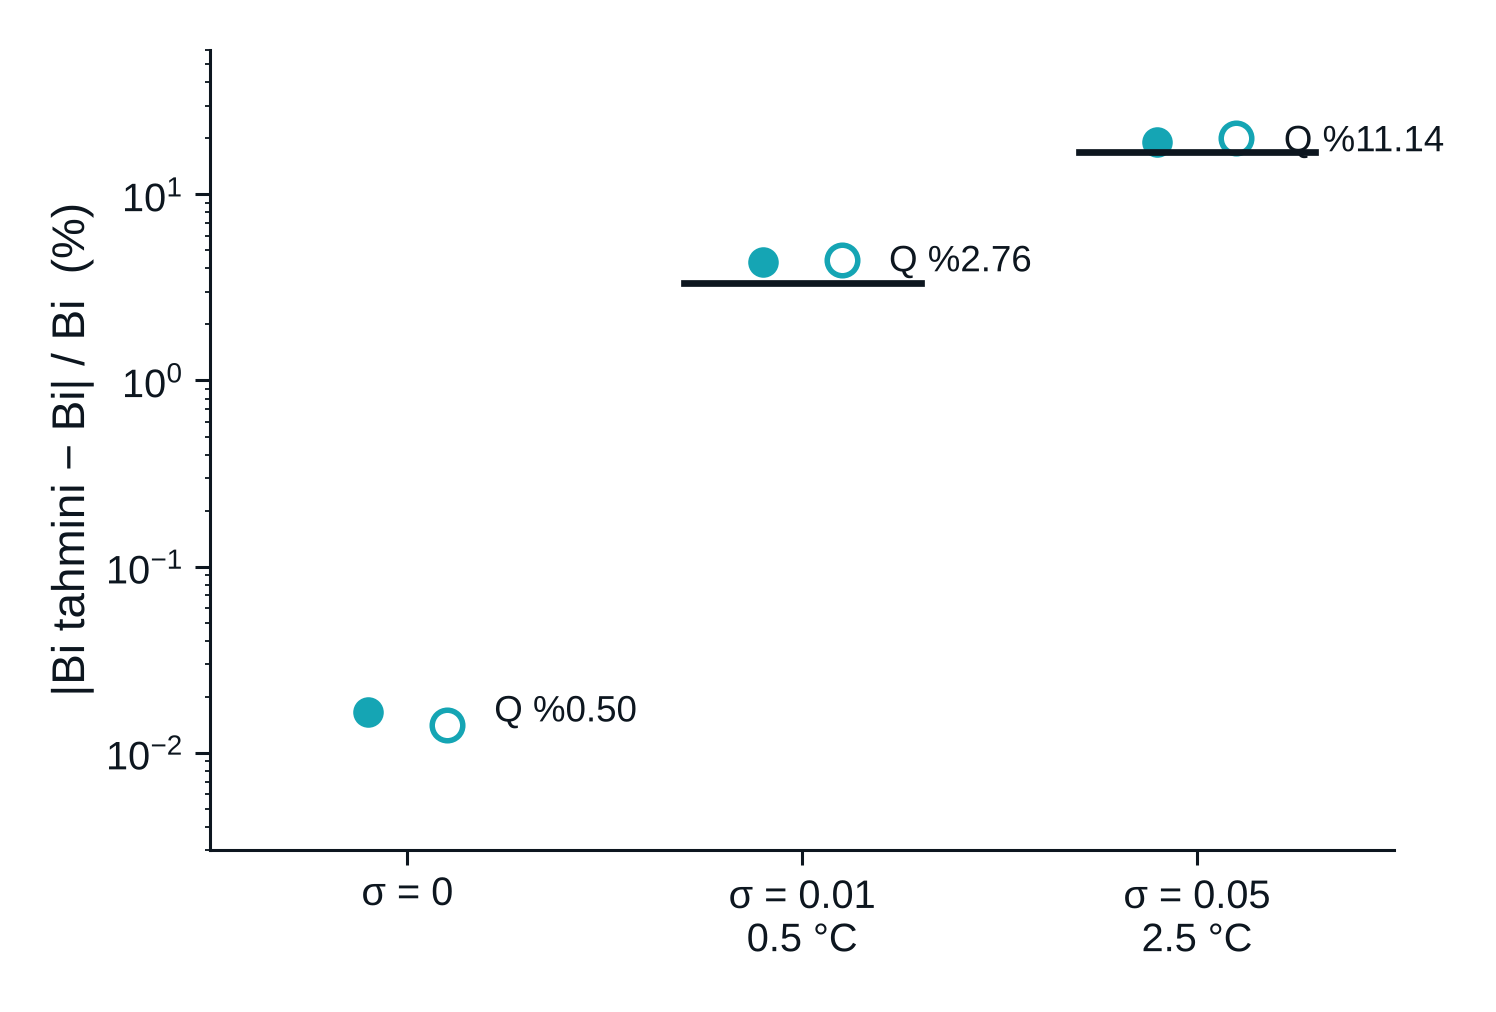

In [15]:
goster("06_noise.png", 560)

In [16]:
V = S["verdict"]
print(f"PINN ters koşu: ~{V['pinn_time_s_median']:.0f} s · FDM + EKK: ~{V['fdm_ls_time_s_median']:.1f} s "
      f"-> {V['pinn_time_s_median'] / V['fdm_ls_time_s_median']:.0f} kat")

PINN ters koşu: ~505 s · FDM + EKK: ~1.0 s -> 526 kat


Bu problemde klasik yöntem aynı doğruluğu yüzlerce kat hızlı veriyor. PINN'in ters problemde anlamlı olduğu yerler:
çözücü pahalı ve türevlenemez olduğunda (her adım bir CFD koşusu), bilinmeyen bir **alan** olduğunda ($h(\xi)$),
ve aynı ağ her Bi için çözüm verdiğinde — parametrik PINN, Ders 05.

## Özet

- $\mathrm{Bi} = e^{s}$ ile Bi'yi ağırlıklarla birlikte öğrenmek tek satır; Bi₀ = 1 ve 10'dan aynı değere yakınsar.
- Ne kadar doğru bulabileceğinizi önce hesaplayın: duyarlılık haritası ve Cramér–Rao sınırı yerleşimi belirler.
- PINN'in Bi hatası gürültü sınırında ve aynı veriyle klasik yöntemle örtüşüyor.
- Köşe tekilliği ters problemde yanlılık olur: köşe Robin noktalarını dışlayın.

## Alıştırmalar

**Lisans:** (1) 10 sensörü alt şeride koyun: önce CRB'yi hesaplayın, sonra PINN ile deneyin ·
(2) Bi₀ = 0.2 ve 25'ten başlatın · (3) $\delta = 0, 0.02, 0.05, 0.1$ taraması.

**Yüksek lisans:** (1) 20 tohumla PINN Bi dağılımının standart sapmasını CRB ile karşılaştırın ·
(2) $h(\xi) = \mathrm{Bi}\,(1 + a\,\xi(1-\xi))$ yapın, $a$'yı da öğrenin · (3) sensör konumlarına ±1 mm hata ekleyin.

In [17]:
# Alıştırma alanı — Lisans 1: 10 sensör alt şeritte
X_b, y_b, _ = sensors(10, "bottom", 0.01, seed=0)
print(f"CRB σ_Bi/Bi = %{100 * crb(X_b, 0.01) / Bi:.2f} · FDM-EKK Bi = {fit_fdm(X_b, y_b)[0]:.3f}")
# model_b, Bi_b, _, _ = pinn_inverse.train(args, X_b, y_b)   # açıp çalıştırın (~2 dk)

CRB σ_Bi/Bi = %1.67 · FDM-EKK Bi = 5.023
